In [1]:
#All the imports
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.stats import norm
from scipy.stats import kurtosis
import fifpy

# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.fields import compute_radial_spectrum
from shared.filtering import iterative_filtering1D, iterative_filtering3D
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("quality_checks", "Spectrum")

In [2]:

def partial_x_2d(f,dx):
    """Compute ∂f/∂x using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dx = np.zeros_like(f)
    
    # Central difference in x-direction (axis=0)
    df_dx[1:Nx-1, :] = (f[2:Nx, :] - f[0:Nx-2, :]) / (2 * dx)
    
    # Periodic boundaries (x-direction)
    df_dx[0, :] = (f[1, :] - f[-1, :]) / (2 * dx)
    df_dx[-1, :] = (f[0, :] - f[-2, :]) / (2 * dx)
    
    return df_dx

def partial_y_2d(f,dy):
    """Compute ∂f/∂y using 2nd-order central differences with periodic BCs."""
    Nx, Ny = f.shape
    df_dy = np.zeros_like(f)
    
    # Central difference in y-direction (axis=1)
    df_dy[:, 1:Ny-1] = (f[:, 2:Ny] - f[:, 0:Ny-2]) / (2 * dy)
    
    # Periodic boundaries (y-direction)
    df_dy[:, 0] = (f[:, 1] - f[:, -1]) / (2 * dy)
    df_dy[:, -1] = (f[:, 0] - f[:, -2]) / (2 * dy)
    
    return df_dy

def partial_x_fft(f, dx):
    """
    Calculate ∂f/∂x using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dx (float): Grid spacing in the x-direction.

    Returns:
        df_dx (2D np.array): Partial derivative ∂f/∂x.
    """
    nx, ny = f.shape
    kx = np.fft.fftfreq(nx, d=dx) * 2 * np.pi  # Wavenumbers in x
    kx = kx[:, np.newaxis]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dx_hat = 1j * kx * f_hat
    df_dx = np.fft.ifft2(df_dx_hat).real

    return np.array(df_dx)

def partial_y_fft(f, dy):
    """
    Calculate ∂f/∂y using FFT on a 2D grid.

    Parameters:
        f (2D np.array): Function values on a 2D grid (shape: Nx × Ny).
        dy (float): Grid spacing in the y-direction.

    Returns:
        df_dy (2D np.array): Partial derivative ∂f/∂y.
    """
    nx, ny = f.shape
    ky = np.fft.fftfreq(ny, d=dy) * 2 * np.pi  # Wavenumbers in y
    ky = ky[np.newaxis, :]                     # Make it 2D for broadcasting

    f_hat = np.fft.fft2(f)
    df_dy_hat = 1j * ky * f_hat
    df_dy = np.fft.ifft2(df_dy_hat).real

    return df_dy



def compute_spectra_at_time(base_path, t, dx, dy):
    File_Bx = f"{base_path}/Bx_ApJ_t{t}.h5"
    File_By = f"{base_path}/By_ApJ_t{t}.h5"
    File_Bz = f"{base_path}/Bz_ApJ_t{t}.h5"
    File_Dn = f"{base_path}/Dn1_ApJ_t{t}.h5"

    with h5py.File(File_Bx, 'r') as fBx, \
         h5py.File(File_By, 'r') as fBy, \
         h5py.File(File_Bz, 'r') as fBz:

        data_Bx = fBx['DS1'][:].T
        data_By = fBy['DS1'][:].T
        data_Bz = fBz['DS1'][:].T

    with h5py.File(File_Dn, 'r') as fDn:
        data_Dn = fDn['DS1'][:].T

    # data_Bx, data_By, data_Bz = iterative_filtering3D(data_Bx, data_By, data_Bz, 3, 2.0)

    # data_Dn = iterative_filtering1D(data_Dn, 2, 2.0)

    # Currents
    data_Jx =  partial_y_fft(data_Bz, dx)
    data_Jy = -partial_x_fft(data_Bz, dx)
    data_Jz =  partial_x_fft(data_By, dx) - partial_y_fft(data_Bx, dx)

    # Spectra
    spectrum_Bx = compute_radial_spectrum(data_Bx, dx, dy)
    spectrum_By = compute_radial_spectrum(data_By, dx, dy)
    spectrum_Bz = compute_radial_spectrum(data_Bz, dx, dy)

    spectrum_Jx = compute_radial_spectrum(data_Jx, dx, dy)
    spectrum_Jy = compute_radial_spectrum(data_Jy, dx, dy)
    spectrum_Jz = compute_radial_spectrum(data_Jz, dx, dy)

    spectrum_B = spectrum_Bx.sp + spectrum_By.sp + spectrum_Bz.sp
    spectrum_J = spectrum_Jx.sp + spectrum_Jy.sp + spectrum_Jz.sp

    spectrum_D = compute_radial_spectrum(data_Dn, dx, dy).sp

    kk = spectrum_Bx.kk  # assume same grid

    return kk, spectrum_B, spectrum_J, spectrum_D

def local_slope(kk, spectrum, window=15, log_spaced=True):
    """
    Sliding power-law fit. Returns the k at each window centre and the
    local spectral slope (power-law index) there.

    window : number of points in each fitting window (odd is convenient)
    """
    logk = np.log10(kk)
    logP = np.log10(spectrum)

    # drop any non-finite points (e.g. P=0 at k=0)
    good = np.isfinite(logk) & np.isfinite(logP)
    logk, logP = logk[good], logP[good]
    kk_good = kk[good]

    half = window // 2
    centres = []
    slopes  = []
    slope_errs = []

    for i in range(half, len(logk) - half):
        sl = slice(i - half, i + half + 1)
        # linear fit: logP = slope * logk + intercept
        coeffs, cov = np.polyfit(logk[sl], logP[sl], 1, cov=True)
        slope = coeffs[0]
        slope_err = np.sqrt(cov[0, 0])
        centres.append(kk_good[i])
        slopes.append(slope)
        slope_errs.append(slope_err)

    return np.array(centres), np.array(slopes), np.array(slope_errs)

In [3]:
# List of simulation directories

dx = 0.0625
dy = 0.0625

In [5]:
indices = np.arange(200,201,5)
indices

array([200])

In [6]:
spectra_B_list = []
spectra_J_list = []
spectra_D_list = []

base_path = f"{DATA_ROOT}/beta_p_1/beta_e_1"

for t in indices:
    kk, spec_B, spec_J, spec_D = compute_spectra_at_time(base_path, t, dx, dy)
    print(t)
    spectra_B_list.append(spec_B)
    spectra_J_list.append(spec_J)
    spectra_D_list.append(spec_D)

200


In [8]:
spectra_B_avg = np.mean(np.array(spectra_B_list), axis=0)
spectra_J_avg = np.mean(np.array(spectra_J_list), axis=0)
spectra_D_avg = np.mean(np.array(spectra_D_list), axis=0)

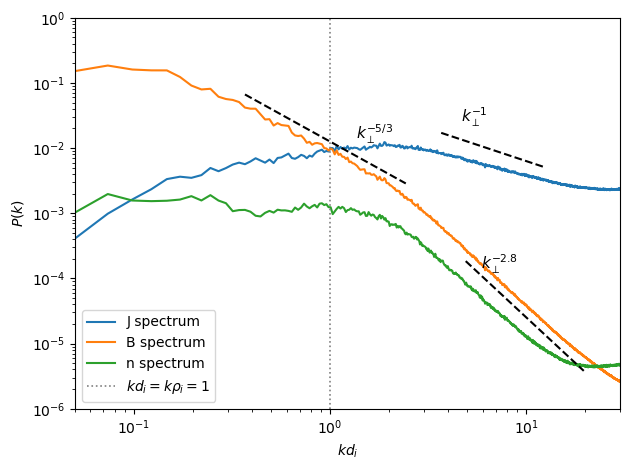

In [9]:
#Plot

plt.loglog(kk, spectra_J_avg, label="J spectrum")
plt.loglog(kk, spectra_B_avg, label="B spectrum")
plt.loglog(kk, spectra_D_avg, label="n spectrum")

# Add slope lines
# k_range_1 = kk[120:350]
k_range_2 = kk[150:500]
k_range_3 = kk[15:100]
k_range_4 = kk[200:800]

# slope_line_1 = 10**(-2.2) * k_range_1**(-3)
slope_line_2 = 10**(-1.2) * k_range_2**(-1)
slope_line_3 = 10**(-1.9) * k_range_3**(-5/3)
slope_line_4 = 10**(-1.8) * k_range_4**(-2.8)

# plt.loglog(k_range_1, slope_line_1, 'k--')
plt.loglog(k_range_2, slope_line_2, 'k--')
plt.loglog(k_range_3, slope_line_3, 'k--')
plt.loglog(k_range_4, slope_line_4, 'k--')

# Inline slope labels
# plt.text(k_range_1[40], slope_line_1[4]*.1, r'$k_\perp^{-3}$', fontsize=11)
plt.text(k_range_2[40], slope_line_2[4]*1.5, r'$k_\perp^{-1}$', fontsize=11)
plt.text(k_range_3[40], slope_line_3[4]*0.3, r'$k_\perp^{-5/3}$', fontsize=11)
plt.text(k_range_4[40], slope_line_4[4]*.8, r'$k_\perp^{-2.8}$', fontsize=11)

# plt.axvline(2*np.pi, color='gray', linestyle=':', linewidth=1.2)
plt.axvline(1, color='gray', linestyle=':', linewidth=1.2, label=r'$kd_i = k\rho_i = 1$')

plt.xlabel(r"$kd_i$")
plt.ylabel(r"$P(k)$")
plt.xlim(5e-2, 30)
plt.ylim(1e-6, 1)

plt.legend()  # <-- this is the key line

plt.tight_layout()
plt.savefig(RESULTS / "JBD_Spectrum", dpi=300)
plt.show()

/tmp/ipykernel_292037/2446105628.py:183: RuntimeWarning: divide by zero encountered in log10
  logk = np.log10(kk)


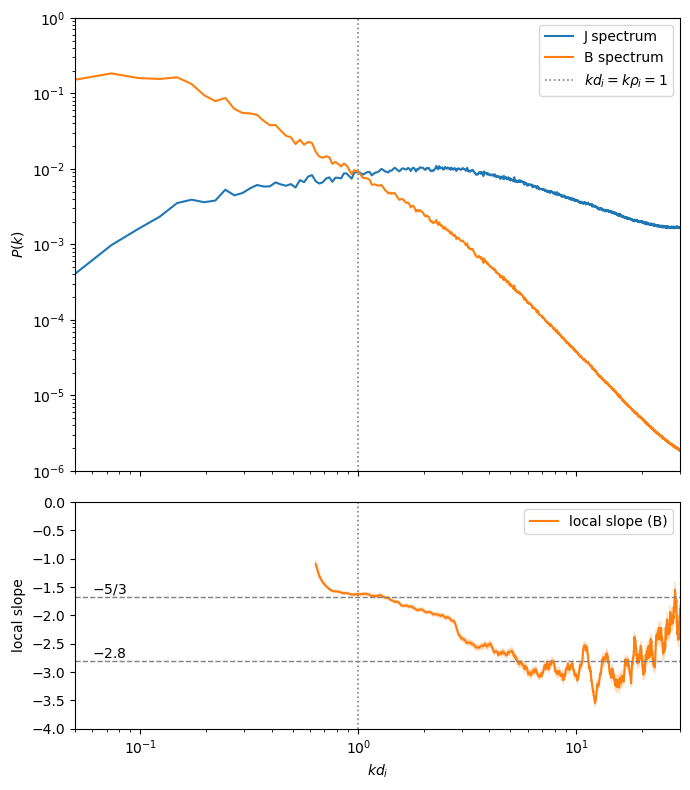

In [16]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 8), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

# --- top: the spectrum ---
ax1.loglog(kk, spectra_J_avg, label="J spectrum")
ax1.loglog(kk, spectra_B_avg, label="B spectrum")
# ax1.loglog(kk, spectra_D_avg, label="n spectrum")
ax1.axvline(1, color='gray', linestyle=':', linewidth=1.2,
            label=r'$kd_i = k\rho_i = 1$')
ax1.set_ylabel(r"$P(k)$")
ax1.set_xlim(5e-2, 30)
ax1.set_ylim(1e-6, 1)
ax1.legend()

# --- bottom: local slope of the B spectrum ---
kc, sl, sl_err = local_slope(kk, spectra_B_avg, window=50)
ax2.semilogx(kc, sl, color='tab:orange', label='local slope (B)')
ax2.fill_between(kc, sl - sl_err, sl + sl_err, color='tab:orange', alpha=0.2)

# reference slope lines
ax2.axhline(-5/3, color='grey', linestyle='--', linewidth=1)
ax2.axhline(-2.8, color='grey', linestyle='--', linewidth=1)
ax2.text(6e-2, -5/3 + 0.05, r'$-5/3$', fontsize=10)
ax2.text(6e-2, -2.8 + 0.05, r'$-2.8$', fontsize=10)

ax2.axvline(1, color='gray', linestyle=':', linewidth=1.2)
ax2.set_xlabel(r"$kd_i$")
ax2.set_ylabel("local slope")
ax2.set_xlim(5e-2, 30)
ax2.set_ylim(-4, 0)
ax2.legend()

plt.tight_layout()
plt.savefig(RESULTS / "JBD_Spectrum_localslope.png", dpi=300)
plt.show()

/tmp/ipykernel_137879/1173858652.py:183: RuntimeWarning: divide by zero encountered in log10
  logk = np.log10(kk)


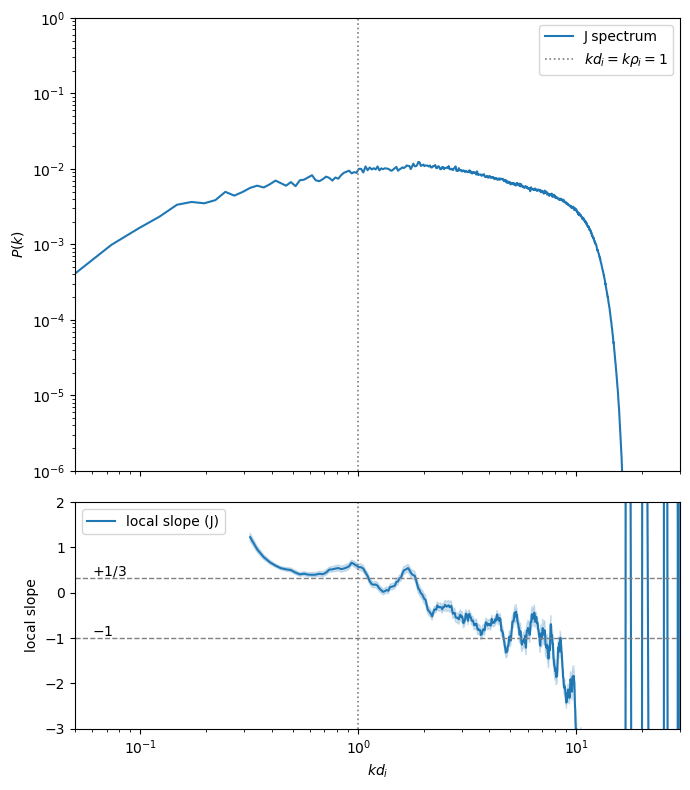

In [14]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 8), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

# --- top: J spectrum ---
ax1.loglog(kk, spectra_J_avg, color='tab:blue', label="J spectrum")
ax1.axvline(1, color='gray', linestyle=':', linewidth=1.2,
            label=r'$kd_i = k\rho_i = 1$')
ax1.set_ylabel(r"$P(k)$")
ax1.set_xlim(5e-2, 30)
ax1.set_ylim(1e-6, 1)
ax1.legend()

# --- bottom: local slope of J ---
kc, sl, sl_err = local_slope(kk, spectra_J_avg, window=25)
ax2.semilogx(kc, sl, color='tab:blue', label='local slope (J)')
ax2.fill_between(kc, sl - sl_err, sl + sl_err, color='tab:blue', alpha=0.2)

# reference slopes (J usually rises then falls — pick lines that fit your case)
ax2.axhline(1/3,  color='grey', linestyle='--', linewidth=1)
ax2.axhline(-1, color='grey', linestyle='--', linewidth=1)
ax2.text(6e-2, 1/3 + 0.05,  r'$+1/3$',  fontsize=10)
ax2.text(6e-2, -1 + 0.05, r'$-1$', fontsize=10)

ax2.axvline(1, color='gray', linestyle=':', linewidth=1.2)
ax2.set_xlabel(r"$kd_i$")
ax2.set_ylabel("local slope")
ax2.set_xlim(5e-2, 30)
ax2.set_ylim(-3, 2)        # J slopes can be positive at low k
ax2.legend()

plt.tight_layout()
plt.savefig(RESULTS / "J_Spectrum_localslope.png", dpi=300)
plt.show()

/tmp/ipykernel_98736/3445050702.py:183: RuntimeWarning: divide by zero encountered in log10
  logk = np.log10(kk)


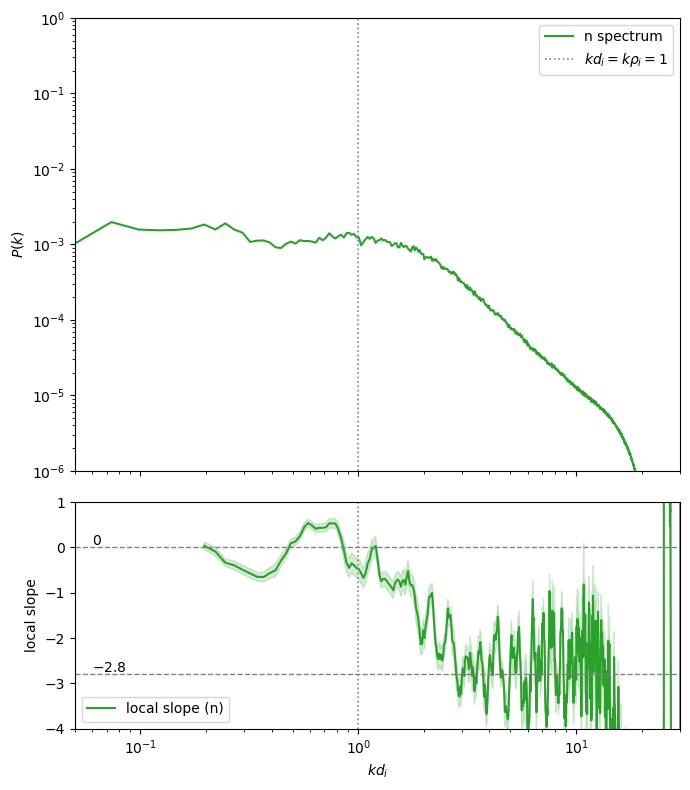

In [35]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 8), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

# --- top: n spectrum ---
ax1.loglog(kk, spectra_D_avg, color='tab:green', label="n spectrum")
ax1.axvline(1, color='gray', linestyle=':', linewidth=1.2,
            label=r'$kd_i = k\rho_i = 1$')
ax1.set_ylabel(r"$P(k)$")
ax1.set_xlim(5e-2, 30)
ax1.set_ylim(1e-6, 1)
ax1.legend()

# --- bottom: local slope of n ---
kc, sl, sl_err = local_slope(kk, spectra_D_avg, window=15)
ax2.semilogx(kc, sl, color='tab:green', label='local slope (n)')
ax2.fill_between(kc, sl - sl_err, sl + sl_err, color='tab:green', alpha=0.2)

ax2.axhline(0, color='grey', linestyle='--', linewidth=1)
ax2.axhline(-2.8, color='grey', linestyle='--', linewidth=1)
ax2.text(6e-2, 0 + 0.05, r'$0$', fontsize=10)
ax2.text(6e-2, -2.8 + 0.05, r'$-2.8$', fontsize=10)

ax2.axvline(1, color='gray', linestyle=':', linewidth=1.2)
ax2.set_xlabel(r"$kd_i$")
ax2.set_ylabel("local slope")
ax2.set_xlim(5e-2, 30)
ax2.set_ylim(-4, 1)
ax2.legend()

plt.tight_layout()
plt.savefig(RESULTS / "n_Spectrum_localslope.png", dpi=300)
plt.show()